HEALTHCARE PATIENT ANALYTICS

GOAL

Data proceesing

Exploratory Data Analysis (EDA) with real-world hospital  data

Data visualization with matplotlib and seaborn

DATASET INFORMATION
Source:https://www.kaggle.com/datasets/abbas829/healthcare-patient-analytics-dataset

Records:5000 patients

Features:12 columns


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("/content/healthcare_patient_analytics_seaborn (1).csv")

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           5000 non-null   int64  
 1   visit_date           5000 non-null   object 
 2   age_group            5000 non-null   object 
 3   gender               5000 non-null   object 
 4   region               5000 non-null   object 
 5   department           5000 non-null   object 
 6   treatment_type       5000 non-null   object 
 7   visit_type           5000 non-null   object 
 8   length_of_stay_days  5000 non-null   float64
 9   treatment_cost       5000 non-null   float64
 10  recovery_score       5000 non-null   float64
 11  readmission_risk     5000 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 468.9+ KB
None


DATA CLEANING

In [ ]:
#CHECK THE DATA SET
df.shape

(5000, 12)

In [ ]:
df.head()

,patient_id,visit_date,age_group,gender,region,department,treatment_type,visit_type,length_of_stay_days,treatment_cost,recovery_score,readmission_risk
0,1,2022-01-01 00:00:00,31-45,Male,West,General Medicine,Medication,Emergency,5.8,59151.0,59.0,0.12
1,2,2022-01-01 01:00:00,60+,Female,West,Orthopedics,Surgery,Routine,5.1,30272.0,97.0,0.11
2,3,2022-01-01 02:00:00,46-60,Male,South,Pediatrics,Observation,Routine,7.9,67498.0,60.0,0.19
3,4,2022-01-01 03:00:00,31-45,Female,North,Neurology,Medication,Routine,5.0,29896.0,51.0,0.47
4,5,2022-01-01 04:00:00,18-30,Female,North,Neurology,Therapy,Routine,0.0,36208.0,60.0,0.40


CHECK MISSING VALUES

In [ ]:
df.isnull().sum()

,0
patient_id,0
visit_date,0
age_group,0
gender,0
region,0
department,0
treatment_type,0
visit_type,0
length_of_stay_days,0
treatment_cost,0


VARIFYING MISSING VALUES

In [ ]:
print("Total missing values:",
      df.isnull().sum().sum())

Total missing values: 0


CHECK DUPLICATE RECORDS

In [ ]:
df.duplicated().sum()

np.int64(0)

CHECKING DATA TYPES

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           5000 non-null   int64  
 1   visit_date           5000 non-null   object 
 2   age_group            5000 non-null   object 
 3   gender               5000 non-null   object 
 4   region               5000 non-null   object 
 5   department           5000 non-null   object 
 6   treatment_type       5000 non-null   object 
 7   visit_type           5000 non-null   object 
 8   length_of_stay_days  5000 non-null   float64
 9   treatment_cost       5000 non-null   float64
 10  recovery_score       5000 non-null   float64
 11  readmission_risk     5000 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 468.9+ KB


Visit_date column is currently saved as object.Convert the column in to date format

In [ ]:
df['visit_date'] =pd.to_datetime(df['visit_date'],errors='coerce')

CHECK THE RESULT:

In [ ]:
df['visit_date'].dtype

dtype('<M8[ns]')

In [ ]:
df['visit_date'].head(10)

,visit_date
0,2022-01-01 00:00:00
1,2022-01-01 01:00:00
2,2022-01-01 02:00:00
3,2022-01-01 03:00:00
4,2022-01-01 04:00:00
5,2022-01-01 05:00:00
6,2022-01-01 06:00:00
7,2022-01-01 07:00:00
8,2022-01-01 08:00:00
9,2022-01-01 09:00:00


CHECK FOR INVALIED VALUES

In [ ]:
#check patient age groups
print(df['age_group'].unique())

['31-45' '60+' '46-60' '18-30']


In [ ]:
#check gender values
print(df['gender'].unique())

['Male' 'Female']


In [ ]:
#check hospital departments
print(df['department'].unique())

['General Medicine' 'Orthopedics' 'Pediatrics' 'Neurology' 'Cardiology']


In [ ]:
#Check treatment types
print(df['treatment_type'].unique())


['Medication' 'Surgery' 'Observation' 'Therapy']


In [ ]:
#check visit types
print(df['visit_type'].unique())

['Emergency' 'Routine']


checking numerical values

In [ ]:
print("Negative length of stay:")
print(df[df['length_of_stay_days'] < 0])

print("Negative treatment cost:")
print(df[df['treatment_cost'] < 0])

print("Recovery scores outside 0-100:")
print(df[~df['recovery_score'].between(0, 100)])

print("Readmission risks outside 0-1:")
print(df[~df['readmission_risk'].between(0, 1)])

Negative length of stay:
Empty DataFrame
Columns: [patient_id, visit_date, age_group, gender, region, department, treatment_type, visit_type, length_of_stay_days, treatment_cost, recovery_score, readmission_risk]
Index: []
Negative treatment cost:
Empty DataFrame
Columns: [patient_id, visit_date, age_group, gender, region, department, treatment_type, visit_type, length_of_stay_days, treatment_cost, recovery_score, readmission_risk]
Index: []
Recovery scores outside 0-100:
Empty DataFrame
Columns: [patient_id, visit_date, age_group, gender, region, department, treatment_type, visit_type, length_of_stay_days, treatment_cost, recovery_score, readmission_risk]
Index: []
Readmission risks outside 0-1:
Empty DataFrame
Columns: [patient_id, visit_date, age_group, gender, region, department, treatment_type, visit_type, length_of_stay_days, treatment_cost, recovery_score, readmission_risk]
Index: []


In [ ]:
#displaying mean,standard deviation,minimum,25th percentile,median(50th percentile),75 percentile and maximum
df.describe()

In [ ]:
#overall treatment cost statistics
df['treatment_cost'].describe()

Check for out liers-Using box plots

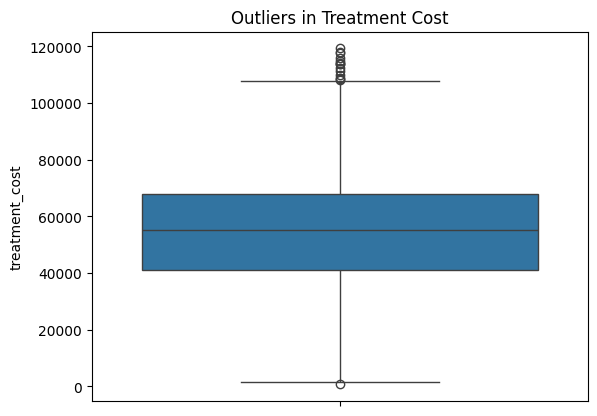

In [ ]:
sns.boxplot(y=df['treatment_cost'])
plt.title('Outliers in Treatment Cost')
plt.show()


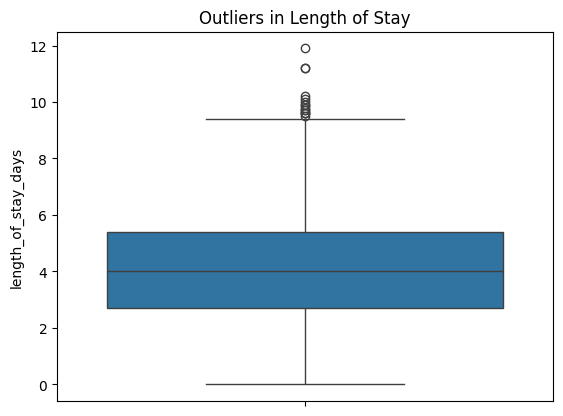

In [ ]:
#check the length of hospital stay
sns.boxplot(y=df['length_of_stay_days'])
plt.title('Outliers in Length of Stay')
plt.show()


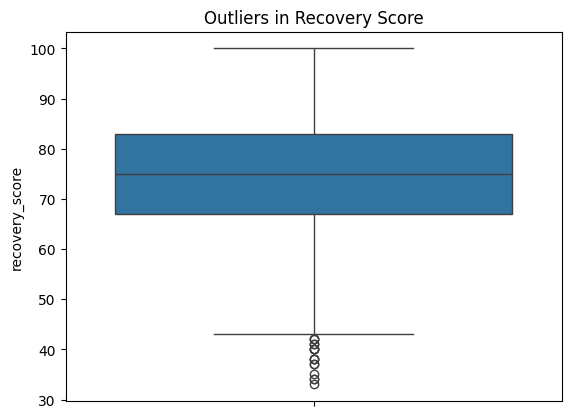

In [ ]:
#check recovery scores
sns.boxplot(y=df['recovery_score'])
plt.title('Outliers in Recovery Score')
plt.show()


Checking cleaned dataset

In [ ]:
#Checking cleaned dataset
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (5000, 12)

Missing values:
0

Duplicate rows:
0

Data types:
patient_id                      int64
visit_date             datetime64[ns]
age_group                      object
gender                         object
region                         object
department                     object
treatment_type                 object
visit_type                     object
length_of_stay_days           float64
treatment_cost                float64
recovery_score                float64
readmission_risk              float64
dtype: object


Creating New columns---visit_year,visit_month,visit_date

In [ ]:
df['visit_year']=df['visit_date'].dt.year
df['visit_month']=df['visit_date'].dt.month
df['visitdate']=df['visit_date'].dt.hour

In [ ]:
df.head()

,patient_id,visit_date,age_group,gender,region,department,treatment_type,visit_type,length_of_stay_days,treatment_cost,recovery_score,readmission_risk,visit_year,visit_month,visitdate
0,1,2022-01-01 00:00:00,31-45,Male,West,General Medicine,Medication,Emergency,5.8,59151.0,59.0,0.12,2022,1,0
1,2,2022-01-01 01:00:00,60+,Female,West,Orthopedics,Surgery,Routine,5.1,30272.0,97.0,0.11,2022,1,1
2,3,2022-01-01 02:00:00,46-60,Male,South,Pediatrics,Observation,Routine,7.9,67498.0,60.0,0.19,2022,1,2
3,4,2022-01-01 03:00:00,31-45,Female,North,Neurology,Medication,Routine,5.0,29896.0,51.0,0.47,2022,1,3
4,5,2022-01-01 04:00:00,18-30,Female,North,Neurology,Therapy,Routine,0.0,36208.0,60.0,0.40,2022,1,4


creating a costperday column

In [ ]:
#checking column names
print(df.columns.tolist())

['patient_id', 'visit_date', 'age_group', 'gender', 'region', 'department', 'treatment_type', 'visit_type', 'length_of_stay_days', 'treatment_cost', 'recovery_score', 'readmission_risk', 'visit_year', 'visit_month', 'visitdate']


In [ ]:
#calculating cost per day

df['cost_per_day'] = df['treatment_cost'] / df['length_of_stay_days']

Catogorizing readmissionrisk into risktiers (Low,Medium,High)

In [ ]:
#checking existing values
print(df['readmission_risk'].unique())

[0.12 0.11 0.19 0.47 0.4  0.07 0.1  0.73 0.04 0.32 0.59 0.29 0.14 0.09
 0.49 0.27 0.28 0.53 0.44 0.57 0.08 0.24 0.63 0.39 0.3  0.36 0.02 0.22
 0.17 0.18 0.43 0.2  0.26 0.61 0.15 0.41 0.16 0.52 0.58 0.72 0.48 0.42
 0.06 0.56 0.31 0.37 0.38 0.01 0.33 0.21 0.45 0.13 0.25 0.46 0.05 0.34
 0.03 0.7  0.35 0.54 0.5  0.77 0.23 0.64 0.65 0.55 0.51 0.67 0.6  0.78
 0.75 0.81 0.66 0.62 0.68 0.79 0.71 0.69 0.74 0.76 0.83 0.82 0.84]


In [ ]:
#checking distrubution
print(df['readmission_risk'].value_counts(dropna = False))

readmission_risk
0.15    142
0.19    140
0.20    133
0.23    129
0.18    124
       ... 
0.78      2
0.82      2
0.76      2
0.81      1
0.84      1
Name: count, Length: 83, dtype: int64


In [ ]:
# Calculate Mean
mean_risk = df['readmission_risk'].mean()

# Calculate Median
median_risk = df['readmission_risk'].median()

# Calculate Mode
mode_risk = df['readmission_risk'].mode()[0]

print("Mean:", mean_risk)
print("Median:", median_risk)
print("Mode:", mode_risk)

Mean: 0.280966
Median: 0.26
Mode: 0.15


Statistcal meassures are:
Mean = 0.28
Median = 0.260
Mode = 0.150

In [ ]:
#finding risk ditrubution
print(df['readmission_risk'].describe())

count    5000.000000
mean        0.280966
std         0.157178
min         0.010000
25%         0.160000
50%         0.260000
75%         0.380000
max         0.840000
Name: readmission_risk, dtype: float64


Percentile values are

25% = 0.16

50% = 0.26

75% = 0.38

Creating Risk Tiers

In [ ]:
# Categorize readmission risk

def categorize_risk(risk):
    if pd.isna(risk):
        return 'Unknown'
    elif risk < 0.16:
        return 'Low'
    elif risk <= 0.38:
        return 'Medium'
    else:
        return 'High'

df['risk_tier'] = df['readmission_risk'].apply(categorize_risk)


In [ ]:
print(df[['readmission_risk','risk_tier']].head(10))

   readmission_risk risk_tier
0              0.12       Low
1              0.11       Low
2              0.19    Medium
3              0.47      High
4              0.40      High
5              0.07       Low
6              0.10       Low
7              0.73      High
8              0.04       Low
9              0.32    Medium


Count patients in each risk tier

In [ ]:
print(df['risk_tier'].value_counts())

risk_tier
Medium    2552
High      1237
Low       1211
Name: count, dtype: int64


VISULIZATIONS

PATIENT DISTRUBUTION BY AGE GROUP-BY BAR CHART

In [ ]:
#check the number of patients in each age group
print(df['age_group'].value_counts())

age_group
31-45    1716
18-30    1283
46-60    1271
60+       730
Name: count, dtype: int64


Patient Distribution by Age Group:
age_group
18-30    1283
31-45    1716
46-60    1271
60+       730
Name: count, dtype: int64


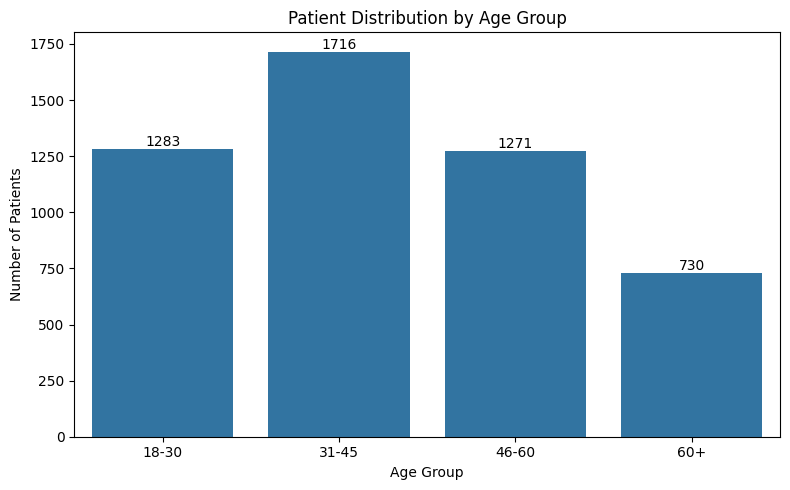

In [ ]:
# Define the correct age group order
age_order = ['18-30', '31-45', '46-60', '60+']

# Count patients in each age group
age_counts = df['age_group'].value_counts().reindex(age_order, fill_value=0)

# Display exact counts
print("Patient Distribution by Age Group:")
print(age_counts)

# Create the bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_counts.index,
    y=age_counts.values
)

plt.title('Patient Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')

# Display the count above each bar
for i, count in enumerate(age_counts.values):
    plt.text(i, count, str(count), ha='center', va='bottom')

plt.tight_layout()
plt.show()


THE FINDINGS:

The number of patient visit highest in the age group :31-45 is 1716

The number of patient visit lowest in the age group  :60+ is 730

PATIENT VISIT BY GENDER

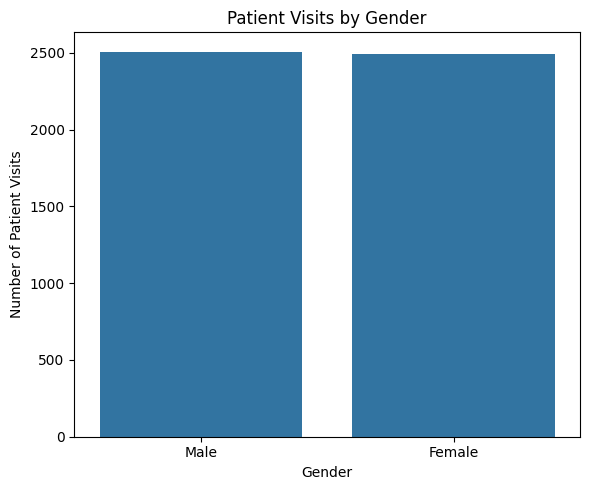

In [ ]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x='gender'
)

plt.title('Patient Visits by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Patient Visits')

plt.tight_layout()
plt.show()

Number of patient visit by gender is approximately same

 can be check by exact counts

In [ ]:
print(df['gender'].value_counts())

gender
Male      2508
Female    2492
Name: count, dtype: int64


Highest patient visit by gender : male
And only 16 patients less in famale

PATIENT VISIT BY HOSPITAL DEPARTMENT

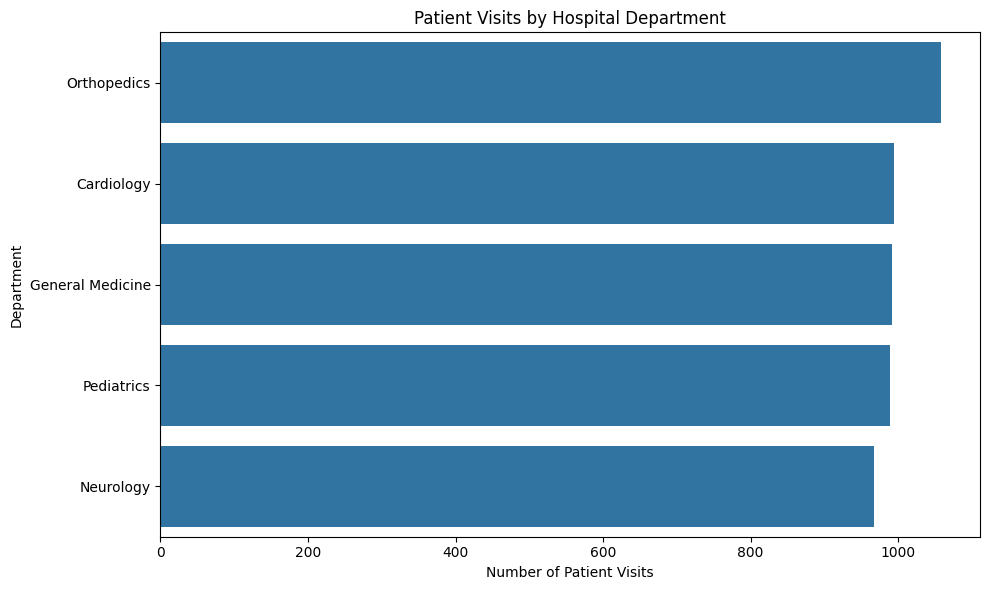

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='department',
    order=df['department'].value_counts().index
)

plt.title('Patient Visits by Hospital Department')
plt.xlabel('Number of Patient Visits')
plt.ylabel('Department')

plt.tight_layout()
plt.show()

Number of patient visit in orthopedics are high,cardiology,general medicine,peadiatrics are approximately same

AVERAGE TREATMENT COST BY DEPARTMENTS

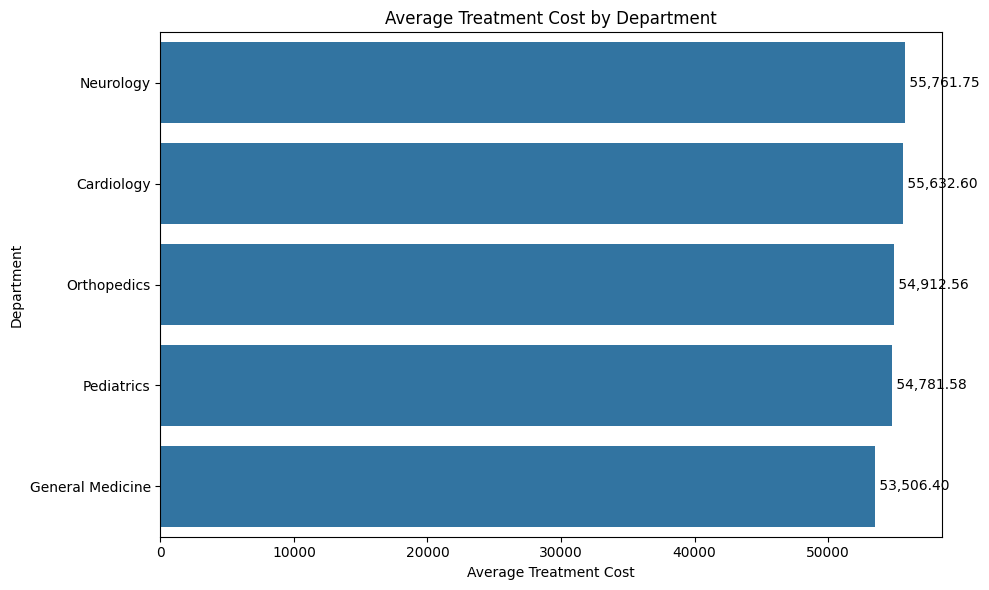

In [ ]:
department_cost = (
    df.groupby('department')['treatment_cost']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

ax=sns.barplot(
    x=department_cost.values,
    y=department_cost.index
)
for i,value in enumerate(department_cost.values):
    ax.text(
      value,
      i,
      f' {value:,.2f}',
      va='center',
      ha='left',
      fontsize=10

  )
plt.title('Average Treatment Cost by Department')
plt.xlabel('Average Treatment Cost')
plt.ylabel('Department')

plt.tight_layout()
plt.show()

Highest Average treatment cost for neurology department (57761.75)

second highest average treatment cost for cardiology department(55632.60)

lowest average treatment cost for general medicine(53506.40)

Average costs in orthopedics is 54912
and for peadiatrics is 54781.58



LENGTH OF HOSPITAL STAY DISTRUBUTION


Checking how long do patients typically stay in the hospital

by histogram

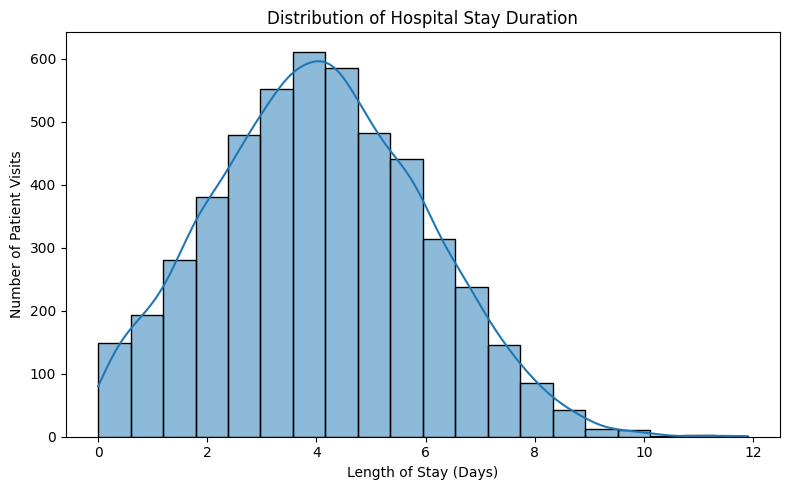

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='length_of_stay_days',
    bins=20,
    kde=True
)

plt.title('Distribution of Hospital Stay Duration')
plt.xlabel('Length of Stay (Days)')
plt.ylabel('Number of Patient Visits')

plt.tight_layout()
plt.show()


Most frequented duration is 4-5 days

most lesser duration in day 12-10

CORRELATION HEATMAP

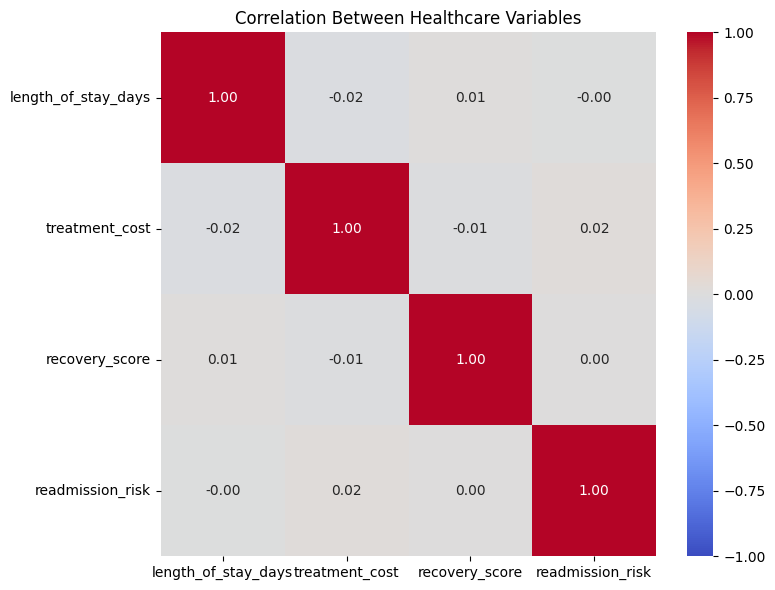

In [ ]:
numeric_df = df[
    [
        'length_of_stay_days',
        'treatment_cost',
        'recovery_score',
        'readmission_risk'
    ]
]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Healthcare Variables')

plt.tight_layout()
plt.show()

Here examind the linear relationships between length of hospital stay,treatment cost and readmission risk

Treatment cost and readmission risk have corelation of approaximately 0.02 no linear association between them

length of hospital stay and treatment cost have a correlation approaximately -0.02.

overall heatmap suggest thatthese variable do not have a strong linear relationship

MONTHLY PATIENT VISIT TREND

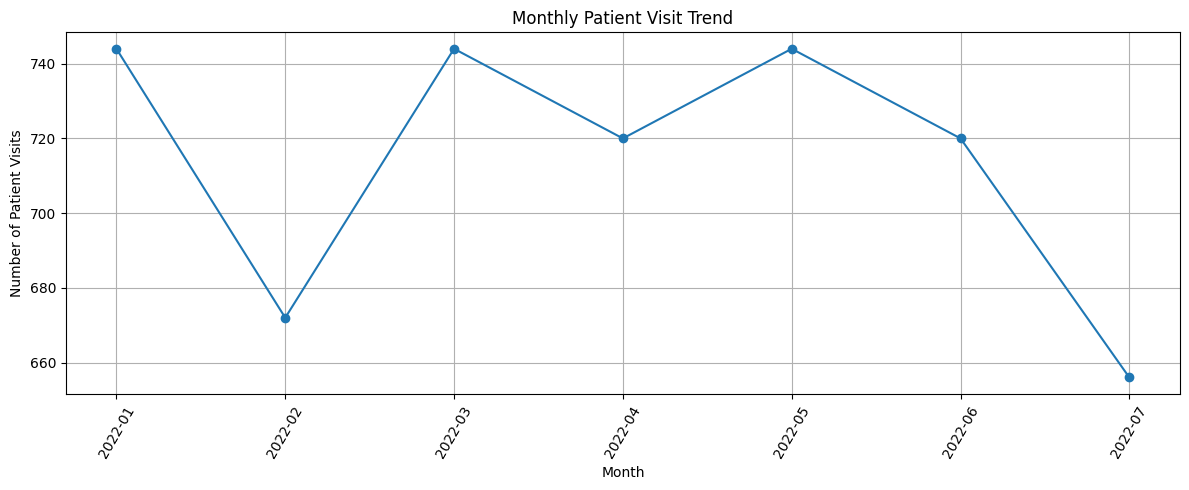

In [ ]:
df['visit_month'] = (
    df['visit_date'].dt.to_period('M')
)

monthly_visits = (
    df.groupby('visit_month')
      .size()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_visits.index.astype(str),
    monthly_visits.values,
    marker='o'
)

plt.title('Monthly Patient Visit Trend')
plt.xlabel('Month')
plt.ylabel('Number of Patient Visits')

plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()



In the month of january,march and may 2022 the patient visit is high above 740

in the month of july 2022 is most month of number of patient visited less  -660

in April,june patient visit is 720

PATIENT VISIT BY TREATMENT TYPE
COUNT PLOT

treatment_type
Observation    1270
Surgery        1262
Medication     1236
Therapy        1232
Name: count, dtype: int64


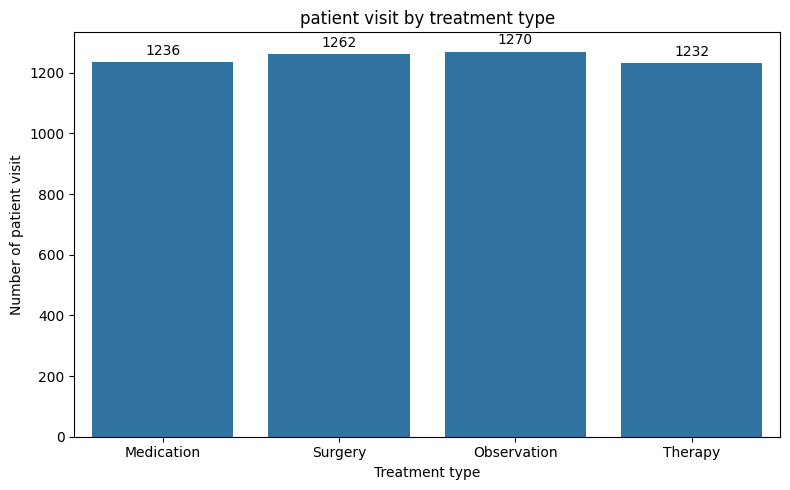

In [ ]:
#Treatment types
print(df['treatment_type'].value_counts())

plt.figure(figsize=(8,5))
ax = sns.countplot(
    data=df,
    x='treatment_type',
    order=['Medication','Surgery','Observation','Therapy']
)
for container in ax.containers:
  ax.bar_label(container,fmt='%d',padding=3)
  plt.title('patient visit by treatment type')
  plt.xlabel('Treatment type')
  plt.ylabel('Number of patient visit')
  plt.tight_layout()
  plt.show()

Patient visit by treatment type shows


1270 patients are visited and treatment given in observation,


1236 patients who takes medications,

1262 patients are taking surgery and

 1232 patients taking Therapy also.




COMPARISON OF EMERGENCY AND ROUTINE VISITS BY BARCHART

Patient Visit by Visit Type:
visit_type
Emergency    1568
Routine      3432
Name: count, dtype: Int64


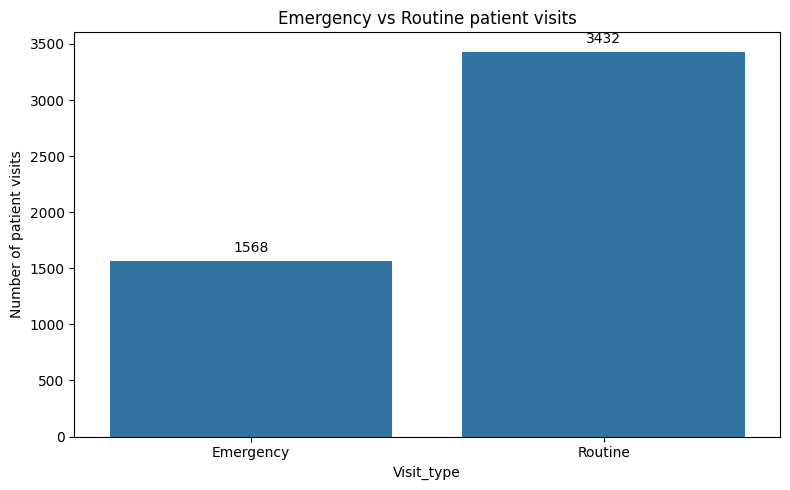

In [ ]:
#count Emergency and Routine visits
visit_counts = (
    df['visit_type'].astype('string')
    .str.strip()
    .str.title()
    .value_counts()
    .reindex(['Emergency','Routine'],fill_value=0)

)
print("Patient Visit by Visit Type:")
print(visit_counts)

plt.figure(figsize=(8,5))
ax=sns.barplot(
    x=visit_counts.index,
    y=visit_counts.values
)
ax.bar_label(ax.containers[0],fmt='%d',padding=4)

plt.title('Emergency vs Routine patient visits')
plt.xlabel('Visit_type')
plt.ylabel('Number of patient visits')
plt.tight_layout()
plt.show()


Emergency vs Routine patient visits barchar shows that


Here 1568 patients are visited for  emergency and 3432 patients are visted for routine checkups

AVERAGE RECOVERY SCORE BY DEPARTMENT -Bar chat

In [ ]:
#average recovery score for departments
department_recovery = (
    df.groupby('department')['recovery_score']
    .mean()
    .sort_values(ascending=False)
)
print("Average Recovery Score by Departments")
print(department_recovery.round(2))

Average Recovery Score by Departments
department
Neurology           75.18
Orthopedics         74.96
General Medicine    74.77
Pediatrics          74.52
Cardiology          74.15
Name: recovery_score, dtype: float64


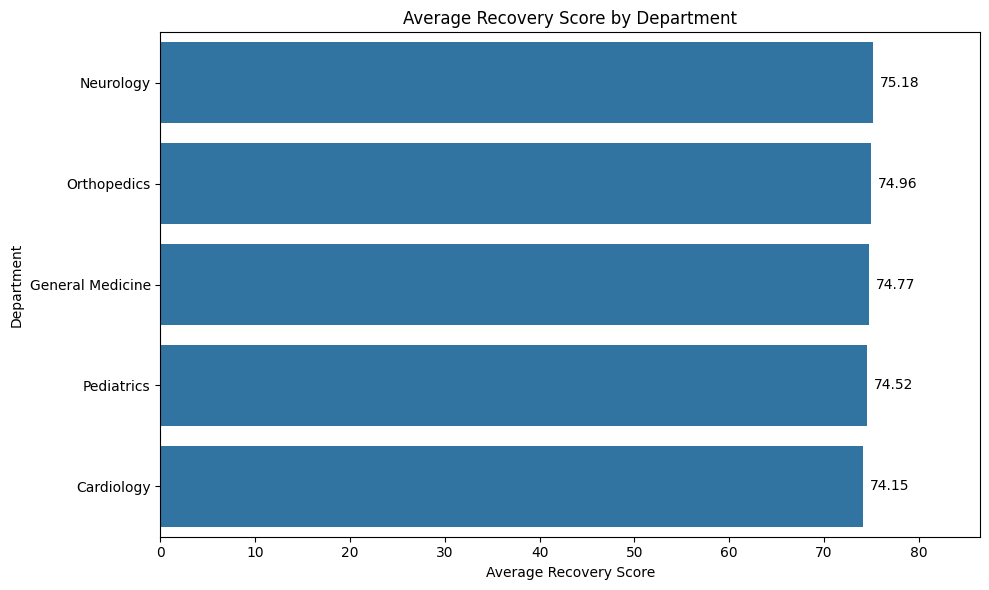

In [ ]:
# Calculate average recovery score by department
department_recovery = (
    df.groupby('department')['recovery_score']
    .mean()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=department_recovery.values,
    y=department_recovery.index
)

# Add a value label to EVERY bar
for bar in ax.patches:
    width = bar.get_width()
    y_position = bar.get_y() + bar.get_height() / 2

    ax.annotate(
        f'{width:.2f}',
        xy=(width, y_position),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=10
    )

# Add space on the right for labels
max_score = department_recovery.max()
plt.xlim(0, max_score * 1.15)

plt.title('Average Recovery Score by Department')
plt.xlabel('Average Recovery Score')
plt.ylabel('Department')

plt.tight_layout()
plt.show()


This barchart is usefull to identify and comapare defferencs in recovery outcomes across departments

Average recovery score in departments between 75.18 and 74.15.

The most average recovery score is for nuerology department.

Histogram of Readmission Risk Scores

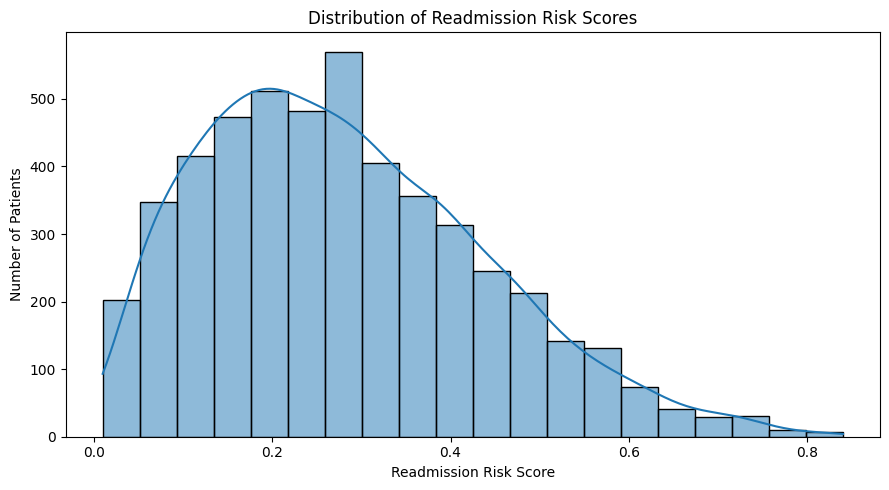

In [ ]:
# Convert readmission risk to numeric if necessary
df['readmission_risk'] = pd.to_numeric(
    df['readmission_risk'], errors='coerce'
)

# Remove missing values for this visualization
risk_scores = df['readmission_risk'].dropna()

# Create histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    risk_scores,
    bins=20,
    kde=True
)

# Add title and axis labels
plt.title('Distribution of Readmission Risk Scores')
plt.xlabel('Readmission Risk Score')
plt.ylabel('Number of Patients')

plt.tight_layout()
plt.show()


Histogram of Readmission risk scores shows a right skewed distrubution of readmission risk scores.

Most patients have scores between approaximately 0.1 and 0.4,while fewer patients have higher scores above 0.5.

This indicates that lower to moderaterisk scores are more common in the data,with relatevely fwe patients having high readmission risk scores

Average Treatment Cost For Medication,Surgery,Observation and Therapy.

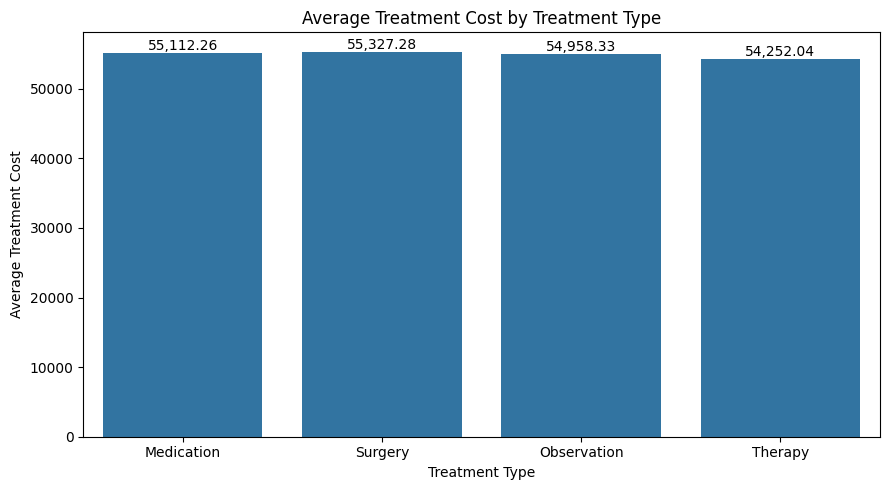

In [ ]:
# Convert treatment cost to numeric
df['treatment_cost'] = pd.to_numeric(
    df['treatment_cost'], errors='coerce'
)

# Calculate average cost for each treatment type
avg_cost = df.groupby('treatment_type')['treatment_cost'].mean()

# Keep the requested treatment types in the chart
treatment_order = ['Medication', 'Surgery', 'Observation', 'Therapy']
avg_cost = avg_cost.reindex(treatment_order)

# Create bar chart
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=avg_cost.index,
    y=avg_cost.values
)

plt.title('Average Treatment Cost by Treatment Type')
plt.xlabel('Treatment Type')
plt.ylabel('Average Treatment Cost')
plt.xticks(rotation=0)

# Display average cost above each bar
for bar in ax.patches:
    height = bar.get_height()
    if pd.notna(height):
        ax.annotate(
            f'{height:,.2f}',
            (bar.get_x() + bar.get_width() / 2, height),
            ha='center',
            va='bottom'
        )

plt.tight_layout()
plt.show()


Bar chart shows that average treatment cost for surgery is 55327.8 it is the highest cost,

 then for medication cost is 55112.26 then for Observation cost about 54958.33 ,

 the lowest average treatment cost is 54252.04 for therapy.